# part 1

## part 1.1

In [3]:
import warnings
warnings.filterwarnings("ignore")
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import joblib

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

In [4]:
BASE_PATH = r"../../models/tuned"

model = joblib.load(f"{BASE_PATH}\\best_lightgbm_model.pkl")

feature_names = joblib.load(f"{BASE_PATH}\\feature_names.pkl")

categorical_cols = joblib.load(f"{BASE_PATH}\\categorical_cols.pkl")

X_valid = joblib.load(f"{BASE_PATH}\\X_valid.pkl")

y_valid = joblib.load(f"{BASE_PATH}\\y_valid.pkl")

y_pred = joblib.load(f"{BASE_PATH}\\y_pred.pkl")

with open(f"{BASE_PATH}\\best_metrics.json", "r") as f:
    metrics = json.load(f)

print("All Day 7 artifacts loaded successfully.")

All Day 7 artifacts loaded successfully.


In [5]:
DAY8_PATH = r"../../data/processed/analysis"
error_df = pd.read_pickle(
    rf"{DAY8_PATH}\error_df.pkl"
)

In [6]:
print(error_df.shape)
print(metrics)
error_df.head()

(4524000, 4)
{'RMSE': 1.2596662880136444, 'MAE': 0.4872918586763616}


,actual,predicted,error,abs_error
0,0,0.028702,0.028702,0.028702
1,0,0.028702,0.028702,0.028702
2,0,0.008814,0.008814,0.008814
3,0,0.010080,0.010080,0.010080
4,0,0.007301,0.007301,0.007301


## part 1.2

In [7]:
error_df.columns.tolist()

['actual', 'predicted', 'error', 'abs_error']

In [8]:
analysis_df = X_valid.copy()

analysis_df["actual"] = y_valid
analysis_df["predicted"] = y_pred

analysis_df["error"] = (
    analysis_df["predicted"]
    - analysis_df["actual"]
)

analysis_df["abs_error"] = (
    analysis_df["error"].abs()
)

In [9]:
analysis_df.columns.tolist()

['item_id',
 'dept_id',
 'cat_id',
 'store_id',
 'state_id',
 'wm_yr_wk',
 'weekday',
 'wday',
 'month',
 'year',
 'event_name_1',
 'event_type_1',
 'event_name_2',
 'event_type_2',
 'snap_CA',
 'snap_TX',
 'snap_WI',
 'sell_price',
 'lag_1',
 'lag_7',
 'lag_14',
 'lag_28',
 'rolling_mean_7',
 'rolling_std_7',
 'rolling_mean_14',
 'rolling_std_14',
 'rolling_mean_28',
 'rolling_std_28',
 'is_weekend',
 'price_lag_1',
 'price_diff_1',
 'price_pct_change',
 'price_max',
 'price_relative_to_max',
 'actual',
 'predicted',
 'error',
 'abs_error']

In [10]:
analysis_df.to_pickle(
    r"../../data/processed/analysis/analysis_df.pkl"
)


In [15]:
print(X_valid.columns.tolist()[:10])

['item_id', 'dept_id', 'cat_id', 'store_id', 'state_id', 'wm_yr_wk', 'weekday', 'wday', 'month', 'year']


In [16]:
analysis_df = X_valid.copy()

analysis_df["actual"] = y_valid
analysis_df["predicted"] = y_pred

analysis_df["error"] = (
    analysis_df["predicted"]
    - analysis_df["actual"]
)

analysis_df["abs_error"] = (
    analysis_df["error"].abs()
)

In [17]:
analysis_df.groupby("store_id").agg(
    bias=("error", "mean"),
    mae=("abs_error", "mean")
)

,bias,mae
store_id,,
CA_1,0.023164,0.471086
CA_3,-0.000867,0.650663
TX_2,0.009304,0.470545
WI_2,0.016702,0.356874


In [22]:
analysis_df = X_valid.copy()

analysis_df["actual"] = y_valid
analysis_df["predicted"] = y_pred

analysis_df["error"] = (
    analysis_df["predicted"] - analysis_df["actual"]
)

analysis_df["abs_error"] = analysis_df["error"].abs()

In [23]:
print("store_id" in analysis_df.columns)

True


In [25]:
store_analysis = (
    analysis_df
    .groupby("store_id")
    .agg(
        observations=("error", "count"),
        bias=("error", "mean"),
        mae=("abs_error", "mean"),
        rmse=("error", lambda x: np.sqrt(np.mean(x**2)))
    )
    .reset_index()
)

store_analysis

,store_id,observations,bias,mae,rmse
0,CA_1,1131000,0.023164,0.471086,0.842683
1,CA_3,1131000,-0.000867,0.650663,1.352573
2,TX_2,1131000,0.009304,0.470545,1.728612
3,WI_2,1131000,0.016702,0.356874,0.905191


In [29]:
dept_analysis = (
    analysis_df
    .groupby("dept_id")
    .agg(
        observations=("error", "count"),
        bias=("error", "mean"),
        mae=("abs_error", "mean"),
        rmse=("error", lambda x: np.sqrt(np.mean(x**2)))
    )
    .reset_index()
    .sort_values("rmse", ascending=False)
)

dept_analysis


,dept_id,observations,bias,mae,rmse
5,HOUSEHOLD_1,640900,-0.074032,0.967997,2.817626
6,HOUSEHOLD_2,3883100,0.026288,0.407952,0.733709
0,FOODS_1,0,NaN,NaN,NaN
1,FOODS_2,0,NaN,NaN,NaN
2,FOODS_3,0,NaN,NaN,NaN
3,HOBBIES_1,0,NaN,NaN,NaN
4,HOBBIES_2,0,NaN,NaN,NaN


In [30]:
analysis_df["dept_id"].value_counts()

dept_id
HOUSEHOLD_2    3883100
HOUSEHOLD_1     640900
FOODS_1              0
FOODS_2              0
FOODS_3              0
HOBBIES_1            0
HOBBIES_2            0
Name: count, dtype: int64

Department-level diagnostics indicate stable performance for HOUSEHOLD_2, while HOUSEHOLD_1 exhibits substantially higher tail risk and a mild underforecasting tendency. Due to hardware-driven parquet partitioning, the validation sample contained only household departments; therefore, these findings should not be generalized to the full M5 hierarchy.



## 1.4

In [31]:
top_errors = (
    analysis_df
    .sort_values("abs_error", ascending=False)
    .head(int(len(analysis_df) * 0.001))
)

print(top_errors.shape)
top_errors.head()

(4524, 38)


,item_id,dept_id,cat_id,store_id,state_id,wm_yr_wk,weekday,wday,month,year,...,is_weekend,price_lag_1,price_diff_1,price_pct_change,price_max,price_relative_to_max,actual,predicted,error,abs_error
2294924,HOUSEHOLD_1_474,HOUSEHOLD_1,HOUSEHOLD,TX_2,TX,11326,Wednesday,5,7,2013,...,0,0.97,0.0,0.0,0.97,1.0,626,10.610743,-615.389257,615.389257
2295008,HOUSEHOLD_1_474,HOUSEHOLD_1,HOUSEHOLD,TX_2,TX,11338,Wednesday,5,10,2013,...,0,0.97,0.0,0.0,0.97,1.0,607,7.696257,-599.303743,599.303743
2295132,HOUSEHOLD_1_474,HOUSEHOLD_1,HOUSEHOLD,TX_2,TX,11403,Monday,3,2,2014,...,0,0.97,0.0,0.0,0.97,1.0,606,14.438136,-591.561864,591.561864
2295304,HOUSEHOLD_1_474,HOUSEHOLD_1,HOUSEHOLD,TX_2,TX,11427,Friday,7,8,2014,...,1,0.97,0.0,0.0,0.97,1.0,567,7.173115,-559.826885,559.826885
2294731,HOUSEHOLD_1_474,HOUSEHOLD_1,HOUSEHOLD,TX_2,TX,11251,Saturday,1,1,2013,...,0,0.97,0.0,0.0,0.97,1.0,480,5.943686,-474.056314,474.056314


In [33]:
top_errors[
    [
        "actual",
        "predicted",
        "error",
        "abs_error",
        "store_id",
        "dept_id",
        "snap_CA",
        "snap_TX",
        "snap_WI",
        "weekday",
        "event_name_1",
        "event_type_1",
        "sell_price"
    ]
].head(20)

,actual,predicted,error,abs_error,store_id,dept_id,snap_CA,snap_TX,snap_WI,weekday,event_name_1,event_type_1,sell_price
2294924,626,10.610743,-615.389257,615.389257,TX_2,HOUSEHOLD_1,0,0,0,Wednesday,No_Event,No_Event,0.97
2295008,607,7.696257,-599.303743,599.303743,TX_2,HOUSEHOLD_1,0,0,0,Wednesday,No_Event,No_Event,0.97
2295132,606,14.438136,-591.561864,591.561864,TX_2,HOUSEHOLD_1,0,0,0,Monday,PresidentsDay,National,0.97
2295304,567,7.173115,-559.826885,559.826885,TX_2,HOUSEHOLD_1,1,0,1,Friday,No_Event,No_Event,0.97
2294731,480,5.943686,-474.056314,474.056314,TX_2,HOUSEHOLD_1,0,1,1,Saturday,No_Event,No_Event,0.97
2294876,474,13.808118,-460.191882,460.191882,TX_2,HOUSEHOLD_1,1,1,1,Thursday,NBAFinalsStart,Sporting,0.97
2295188,372,5.104664,-366.895336,366.895336,TX_2,HOUSEHOLD_1,0,0,1,Monday,No_Event,No_Event,0.97
2295274,347,6.852506,-340.147494,340.147494,TX_2,HOUSEHOLD_1,1,1,1,Wednesday,No_Event,No_Event,0.97
2295240,345,6.913982,-338.086018,338.086018,TX_2,HOUSEHOLD_1,1,1,1,Thursday,NBAFinalsStart,Sporting,0.97
2295360,303,3.927942,-299.072058,299.072058,TX_2,HOUSEHOLD_1,1,1,1,Friday,No_Event,No_Event,0.97


Extreme residuals are highly concentrated within the TX_2 / HOUSEHOLD_1 segment and correspond to abrupt demand explosions that are largely unexplained by the available calendar, SNAP, and pricing features. This suggests that the dominant source of forecasting risk is missing causal information rather than global model misspecification.

In [34]:
event_analysis = (
    analysis_df
    .groupby("event_type_1")
    .agg(
        observations=("error", "count"),
        mae=("abs_error", "mean"),
        rmse=("error", lambda x: np.sqrt(np.mean(x**2))),
        bias=("error", "mean")
    )
    .sort_values("rmse", ascending=False)
)

event_analysis

,observations,mae,rmse,bias
event_type_1,,,,
Sporting,36000,0.499976,3.156746,0.015480
National,120000,0.443111,1.948740,-0.005015
No_Event,4161600,0.488854,1.216074,0.012304
Religious,124800,0.477688,1.029171,0.019287
Cultural,81600,0.481685,0.974762,0.013021


In [35]:
for snap_col in ["snap_CA", "snap_TX", "snap_WI"]:
    print("\n", snap_col)

    print(
        analysis_df
        .groupby(snap_col)
        .agg(
            mae=("abs_error", "mean"),
            rmse=("error",
                  lambda x: np.sqrt(np.mean(x**2)))
        )
    )


 snap_CA
              mae      rmse
snap_CA                    
0        0.479702  1.233620
1        0.502777  1.311206

 snap_TX
              mae      rmse
snap_TX                    
0        0.481169  1.251956
1        0.499785  1.275254

 snap_WI
              mae      rmse
snap_WI                    
0        0.481507  1.198596
1        0.499095  1.375887


In [36]:
importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
})

importance_df = (
    importance_df
    .sort_values("importance", ascending=False)
)

importance_df.head(20)

,feature,importance
0,item_id,4165
18,lag_1,3520
22,rolling_mean_7,2298
5,wm_yr_wk,2159
19,lag_7,2079
21,lag_28,1944
20,lag_14,1898
24,rolling_mean_14,1288
8,month,1200
26,rolling_mean_28,1175


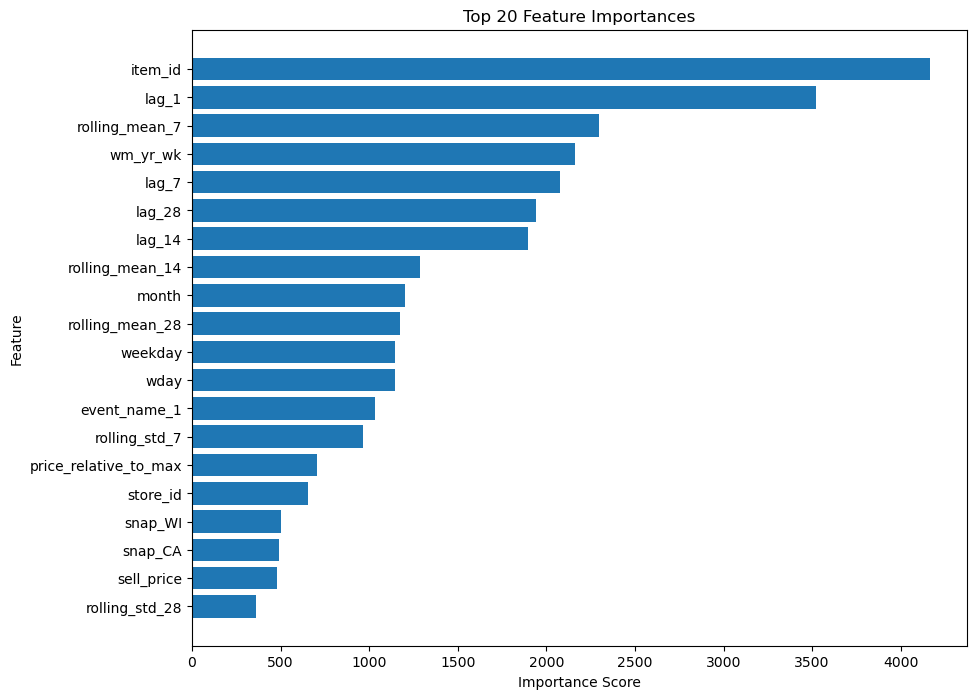

In [37]:
top_features = importance_df.head(20)

plt.figure(figsize=(10,8))

plt.barh(
    top_features["feature"][::-1],
    top_features["importance"][::-1]
)

plt.title("Top 20 Feature Importances")
plt.xlabel("Importance Score")
plt.ylabel("Feature")

plt.show()